In [2]:

import pandas as pd
from pathlib import Path

# Find the project folder
current = Path.cwd()

if current.name == "notebooks":
    project_path = current.parent
else:
    project_path = current

# Location of the collision dataset
file_path = project_path / "data" / "raw" / "dft-road-casualty-statistics-collision-2025.csv"

# Read the dataset
df = pd.read_csv(file_path, low_memory=False)

# Display dataset information
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first 5 rows
display(df.head())



ModuleNotFoundError: No module named 'pandas'

ModuleNotFoundError: No module named 'pandas'

In [1]:
import sys
print(sys.executable)


C:\Users\ECC\AppData\Local\Programs\Python\Python311\python.exe


In [2]:

import pandas as pd
from pathlib import Path

# Find the project folder
current = Path.cwd()
project_path = current.parent if current.name == "notebooks" else current

# Collision dataset location
file_path = project_path / "data" / "raw" / "dft-road-casualty-statistics-collision-2025.csv"

# Load the dataset
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 101525
Number of columns: 44


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,...,-1,0,2,3,2,E01012468,3,1,0.0,1.0
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,...,-1,0,2,1,1,E01012551,3,1,0.0,1.0


In [3]:

# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Check accident severity distribution
print("\nAccident Severity Distribution:")
print(df["collision_severity"].value_counts().sort_index())


Dataset Columns:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'collisio

In [4]:

# Create a working copy without changing the original data
apriori_df = df.copy()

# Merge Fatal and Serious into Severe
severity_mapping = {
    1: "Severe",
    2: "Severe",
    3: "Slight"
}

apriori_df["severity_group"] = apriori_df["collision_severity"].map(severity_mapping)

# Display the new severity distribution
print("New Severity Distribution:")
print(apriori_df["severity_group"].value_counts())

# Calculate the percentage of severe accidents
severe_percentage = (
    (apriori_df["severity_group"] == "Severe").mean() * 100
)

print(f"\nSevere Accidents Percentage: {severe_percentage:.2f}%")


New Severity Distribution:
severity_group
Slight    74881
Severe    26644
Name: count, dtype: int64

Severe Accidents Percentage: 26.24%


In [5]:

# STEP 11: Binning numerical variables

# 1. Extract hour from accident time
apriori_df["hour"] = pd.to_datetime(
    apriori_df["time"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
).dt.hour

# 2. Group hours into time periods
apriori_df["time_group"] = pd.cut(
    apriori_df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# 3. Group speed limits
speed = pd.to_numeric(
    apriori_df["speed_limit"], errors="coerce"
)
speed = speed.where(speed > 0)

apriori_df["speed_group"] = pd.cut(
    speed,
    bins=[0, 30, 50, float("inf")],
    labels=["Low", "Medium", "High"]
)

# 4. Group number of vehicles
vehicles = pd.to_numeric(
    apriori_df["number_of_vehicles"], errors="coerce"
)
vehicles = vehicles.where(vehicles >= 1)

apriori_df["vehicles_group"] = pd.cut(
    vehicles,
    bins=[0, 1, 2, float("inf")],
    labels=["1 Vehicle", "2 Vehicles", "3+ Vehicles"]
)

# Display the results
display(apriori_df[
    ["time", "time_group", "speed_limit",
     "speed_group", "number_of_vehicles",
     "vehicles_group"]
].head(10))

print("\nTime Distribution:")
print(apriori_df["time_group"].value_counts())

print("\nSpeed Distribution:")
print(apriori_df["speed_group"].value_counts())

print("\nMissing values after binning:")
print(apriori_df[
    ["time_group", "speed_group", "vehicles_group"]
].isna().sum())


,time,time_group,speed_limit,speed_group,number_of_vehicles,vehicles_group
0,15:00,Afternoon,30,Low,1,1 Vehicle
1,09:35,Morning,30,Low,2,2 Vehicles
2,18:18,Evening,30,Low,2,2 Vehicles
3,16:30,Afternoon,40,Medium,2,2 Vehicles
4,07:45,Morning,70,High,7,3+ Vehicles
5,12:11,Afternoon,30,Low,1,1 Vehicle
6,11:45,Morning,30,Low,2,2 Vehicles
7,17:31,Afternoon,30,Low,2,2 Vehicles
8,16:00,Afternoon,20,Low,1,1 Vehicle
9,16:40,Afternoon,60,High,2,2 Vehicles



Time Distribution:
time_group
Afternoon    44365
Morning      26843
Evening      24734
Night         5583
Name: count, dtype: int64

Speed Distribution:
speed_group
Low       69718
High      18309
Medium    13498
Name: count, dtype: int64

Missing values after binning:
time_group        0
speed_group       0
vehicles_group    0
dtype: int64


In [6]:

# STEP 11: Binning

# Extract the hour from accident time
apriori_df["hour"] = pd.to_datetime(
    apriori_df["time"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
).dt.hour

# Group hours
apriori_df["time_group"] = pd.cut(
    apriori_df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# Group speed limits
speed = pd.to_numeric(
    apriori_df["speed_limit"], errors="coerce"
).where(lambda x: x > 0)

apriori_df["speed_group"] = pd.cut(
    speed,
    bins=[0, 30, 50, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Group number of vehicles
vehicles = pd.to_numeric(
    apriori_df["number_of_vehicles"], errors="coerce"
).where(lambda x: x >= 1)

apriori_df["vehicles_group"] = pd.cut(
    vehicles,
    bins=[0, 1, 2, float("inf")],
    labels=["1 Vehicle", "2 Vehicles", "3+ Vehicles"]
)

# Show results
display(apriori_df[
    ["time", "time_group", "speed_limit",
     "speed_group", "number_of_vehicles",
     "vehicles_group"]
].head(10))

print("\nTime Groups:")
print(apriori_df["time_group"].value_counts())

print("\nSpeed Groups:")
print(apriori_df["speed_group"].value_counts())

print("\nMissing Values:")
print(apriori_df[
    ["time_group", "speed_group", "vehicles_group"]
].isna().sum())


,time,time_group,speed_limit,speed_group,number_of_vehicles,vehicles_group
0,15:00,Afternoon,30,Low,1,1 Vehicle
1,09:35,Morning,30,Low,2,2 Vehicles
2,18:18,Evening,30,Low,2,2 Vehicles
3,16:30,Afternoon,40,Medium,2,2 Vehicles
4,07:45,Morning,70,High,7,3+ Vehicles
5,12:11,Afternoon,30,Low,1,1 Vehicle
6,11:45,Morning,30,Low,2,2 Vehicles
7,17:31,Afternoon,30,Low,2,2 Vehicles
8,16:00,Afternoon,20,Low,1,1 Vehicle
9,16:40,Afternoon,60,High,2,2 Vehicles



Time Groups:
time_group
Afternoon    44365
Morning      26843
Evening      24734
Night         5583
Name: count, dtype: int64

Speed Groups:
speed_group
Low       69718
High      18309
Medium    13498
Name: count, dtype: int64

Missing Values:
time_group        0
speed_group       0
vehicles_group    0
dtype: int64


In [7]:

# STEP 12: One-Hot Encoding

# Select accident conditions for Apriori
selected_columns = [
    "time_group",
    "speed_group",
    "vehicles_group",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

features = apriori_df[selected_columns].copy()

# Handle missing or invalid categorical values
categorical_columns = [
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

for col in categorical_columns:
    features[col] = (
        features[col].astype("string").str.strip()
    )

    features[col] = features[col].replace({
        "-1": pd.NA,
        "": pd.NA,
        "nan": pd.NA
    })

# Convert categories into True/False columns
transactions = pd.get_dummies(
    features,
    prefix_sep="=",
    dtype=bool
)

# Add Severe as our target
transactions["Severity=Severe"] = (
    apriori_df["severity_group"] == "Severe"
).to_numpy()

print("One-Hot Encoding Completed!")

print("Number of accidents:", transactions.shape[0])
print("Number of encoded columns:", transactions.shape[1])

print("Severe accidents:",
      transactions["Severity=Severe"].sum())

display(transactions.head())


One-Hot Encoding Completed!
Number of accidents: 101525
Number of encoded columns: 40
Severe accidents: 26644


,time_group=Night,time_group=Morning,time_group=Afternoon,time_group=Evening,speed_group=Low,speed_group=Medium,speed_group=High,vehicles_group=1 Vehicle,vehicles_group=2 Vehicles,vehicles_group=3+ Vehicles,...,road_surface_conditions=1,road_surface_conditions=2,road_surface_conditions=3,road_surface_conditions=4,road_surface_conditions=5,road_surface_conditions=9,urban_or_rural_area=1,urban_or_rural_area=2,urban_or_rural_area=3,Severity=Severe
0,False,False,True,False,True,False,False,True,False,False,...,True,False,False,False,False,False,True,False,False,False
1,False,True,False,False,True,False,False,False,True,False,...,True,False,False,False,False,False,True,False,False,False
2,False,False,False,True,True,False,False,False,True,False,...,False,True,False,False,False,False,False,True,False,False
3,False,False,True,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,True,False,False
4,False,True,False,False,False,False,True,False,False,True,...,False,True,False,False,False,False,False,True,False,False


In [8]:

# STEP 13: Apply Apriori Algorithm

from mlxtend.frequent_patterns import apriori

# Check that One-Hot Encoding is completed
assert "Severity=Severe" in transactions.columns

# Set Apriori parameters
min_support = 0.005
max_length = 3

# Run Apriori
frequent_itemsets = apriori(
    transactions,
    min_support=min_support,
    use_colnames=True,
    max_len=max_length,
    low_memory=True
)

# Sort results by support
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

print("Apriori completed successfully!")
print("Number of frequent itemsets:", len(frequent_itemsets))

# Display top 10 frequent itemsets
display(frequent_itemsets.head(10))


Apriori completed successfully!
Number of frequent itemsets: 1569


,support,itemsets
0,0.821522,frozenset({weather_conditions=1})
1,0.745422,frozenset({road_surface_conditions=1})
2,0.730362,frozenset({road_type=6})
3,0.717203,frozenset({light_conditions=1})
4,0.708367,"frozenset({road_surface_conditions=1, weather_..."
5,0.686708,frozenset({speed_group=Low})
6,0.661394,frozenset({urban_or_rural_area=1})
7,0.616508,"frozenset({weather_conditions=1, light_conditi..."
8,0.609397,frozenset({vehicles_group=2 Vehicles})
9,0.607791,"frozenset({weather_conditions=1, road_type=6})"


In [9]:

# STEP 14: Generate Association Rules

from mlxtend.frequent_patterns import association_rules

if frequent_itemsets.empty:
    raise ValueError("No frequent itemsets found. Check Step 13.")

# Generate rules using minimum confidence
rules = association_rules(
    frequent_itemsets,
    num_itemsets=len(transactions),
    metric="confidence",
    min_threshold=0.15
)

print("Total association rules:", len(rules))

# Select rules ending ONLY in Severe
target = frozenset({"Severity=Severe"})

severe_rules = rules[
    rules["consequents"].apply(lambda x: x == target)
].copy()

print("Rules ending in Severe:", len(severe_rules))

display(severe_rules[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(10))


Total association rules: 4636
Rules ending in Severe: 198


,antecedents,consequents,support,confidence,lift
384,frozenset({weather_conditions=1}),frozenset({Severity=Severe}),0.220005,0.267802,1.020439
417,frozenset({road_type=6}),frozenset({Severity=Severe}),0.203960,0.279258,1.064093
434,frozenset({road_surface_conditions=1}),frozenset({Severity=Severe}),0.196296,0.263336,1.003422
466,"frozenset({road_surface_conditions=1, weather_...",frozenset({Severity=Severe}),0.188446,0.266029,1.013684
484,frozenset({light_conditions=1}),frozenset({Severity=Severe}),0.181670,0.253303,0.965192
531,"frozenset({weather_conditions=1, road_type=6})",frozenset({Severity=Severe}),0.172381,0.283619,1.080710
596,frozenset({speed_group=Low}),frozenset({Severity=Severe}),0.165516,0.241028,0.918420
612,"frozenset({weather_conditions=1, light_conditi...",frozenset({Severity=Severe}),0.159833,0.259255,0.987870
630,frozenset({urban_or_rural_area=1}),frozenset({Severity=Severe}),0.157872,0.238697,0.909536
675,"frozenset({road_surface_conditions=1, road_typ...",frozenset({Severity=Severe}),0.152603,0.278902,1.062735


In [10]:

# STEP 15: Rank Severe Rules by Lift

# Keep positive associations
severe_rules = severe_rules[
    severe_rules["lift"] > 1
].copy()

# Sort by lift, confidence and support
severe_rules = severe_rules.sort_values(
    ["lift", "confidence", "support"],
    ascending=[False, False, False]
)

# Convert rule conditions into readable text
severe_rules["Conditions"] = severe_rules[
    "antecedents"
].apply(lambda x: " AND ".join(sorted(x)))

# Final results table
top_rules = severe_rules[
    ["Conditions", "support", "confidence", "lift"]
].head(10).copy()

print("Positive Severe Rules:", len(severe_rules))

display(top_rules.round(3))


Positive Severe Rules: 114


,Conditions,support,confidence,lift
4635,speed_group=High AND time_group=Night,0.005,0.402,1.530
3598,speed_group=Medium AND vehicles_group=1 Vehicle,0.011,0.394,1.500
3732,time_group=Night AND vehicles_group=1 Vehicle,0.010,0.387,1.474
3237,light_conditions=6 AND weather_conditions=1,0.015,0.383,1.459
3653,light_conditions=6 AND road_surface_conditions=1,0.011,0.379,1.443
2891,speed_group=High AND vehicles_group=1 Vehicle,0.021,0.378,1.442
3343,light_conditions=6 AND speed_group=High,0.014,0.378,1.438
1999,road_type=6 AND speed_group=High,0.043,0.377,1.436
3133,light_conditions=6 AND road_type=6,0.017,0.376,1.433
4124,time_group=Night AND urban_or_rural_area=2,0.008,0.374,1.426


Matplotlib is building the font cache; this may take a moment.


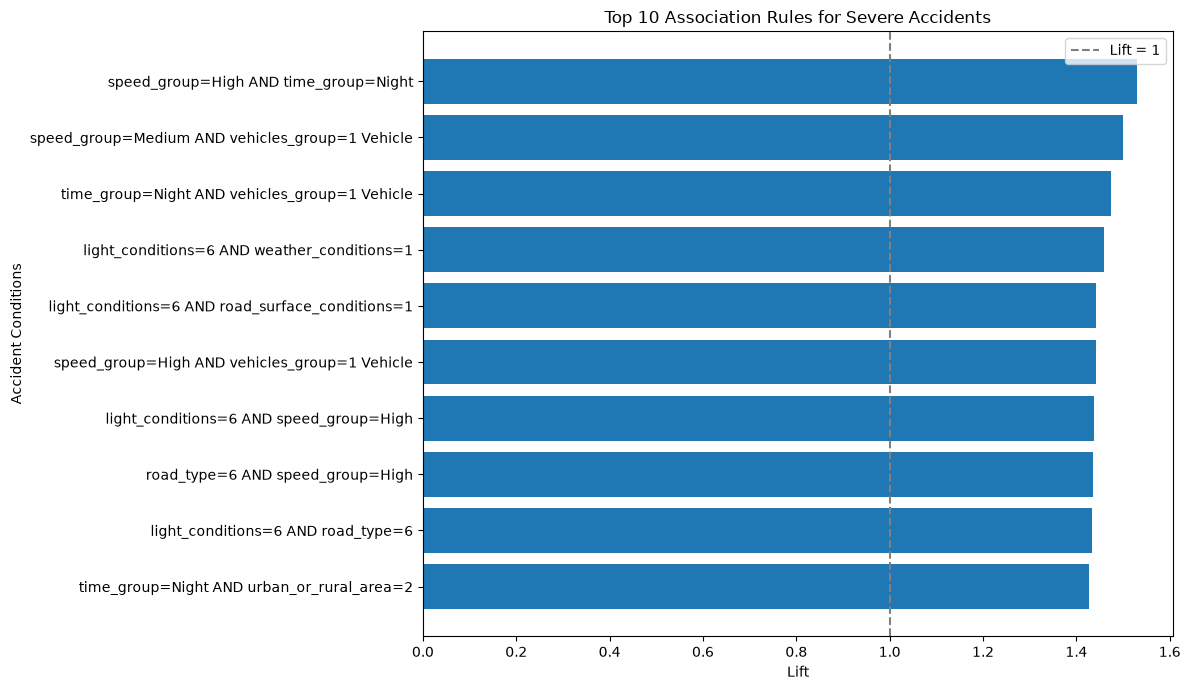

In [11]:

# STEP 16: Visualize Top Rules

import matplotlib.pyplot as plt

if top_rules.empty:
    print("No positive Severe rules found.")
else:
    plot_data = top_rules.sort_values("lift")

    plt.figure(figsize=(12, 7))

    plt.barh(
        plot_data["Conditions"],
        plot_data["lift"]
    )

    plt.axvline(
        x=1,
        color="gray",
        linestyle="--",
        label="Lift = 1"
    )

    plt.xlabel("Lift")
    plt.ylabel("Accident Conditions")
    plt.title("Top 10 Association Rules for Severe Accidents")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [12]:

# STEP 17: Evaluate Apriori Results

baseline = transactions["Severity=Severe"].mean()

print(f"Total accidents: {len(transactions):,}")
print(f"Baseline Severe Rate: {baseline:.2%}")
print(f"Minimum Support: {min_support}")
print(f"Frequent Itemsets: {len(frequent_itemsets)}")
print(f"Positive Severe Rules: {len(severe_rules)}")

if not top_rules.empty:
    print("\nStrongest Rule:")
    best = top_rules.iloc[0]

    print("Conditions:", best["Conditions"])
    print(f"Support: {best['support']:.2%}")
    print(f"Confidence: {best['confidence']:.2%}")
    print(f"Lift: {best['lift']:.3f}")

    print(
        "\nExpected severe accident count for this rule:",
        round(best["support"] * len(transactions))
    )


Total accidents: 101,525
Baseline Severe Rate: 26.24%
Minimum Support: 0.005
Frequent Itemsets: 1569
Positive Severe Rules: 114

Strongest Rule:
Conditions: speed_group=High AND time_group=Night
Support: 0.50%
Confidence: 40.16%
Lift: 1.530

Expected severe accident count for this rule: 508


In [1]:

# STEP 22: Load the Clean Dataset

import pandas as pd

# Load the clean dataset
clean_df = pd.read_csv(
    r"C:\Users\ECC\Documents\traffic-accident-patterns\data\clean\accidents_clean.csv",
    dtype={"accident_index": str}
)

# Check dataset information
print("Clean Dataset Loaded Successfully!")
print("Number of rows:", clean_df.shape[0])
print("Number of columns:", clean_df.shape[1])

print("\nMissing Values:")
print(clean_df.isnull().sum().sum())

print("\nAccident Severity Distribution:")
print(clean_df["accident_severity"].value_counts())

# Display first 5 rows
display(clean_df.head())


Clean Dataset Loaded Successfully!
Number of rows: 101523
Number of columns: 15

Missing Values:
0

Accident Severity Distribution:
accident_severity
Slight     74880
Serious    25190
Fatal       1453
Name: count, dtype: int64


,accident_index,latitude,longitude,hour,weekday,month,speed_limit,road_type,light_conditions,weather_conditions,road_surface_conditions,urban_or_rural_area,number_of_vehicles,number_of_casualties,accident_severity
0,202517M101925,54.56650,-1.26420,15,Tuesday,2,30,Single carriageway,Daylight,Fine,Dry,Urban,1,1,Slight
1,202517L205225,54.55967,-1.15704,9,Wednesday,5,30,Single carriageway,Daylight,Fine,Dry,Urban,2,1,Slight
2,2025070971700,53.33884,-2.68516,18,Thursday,11,30,Single carriageway,Darkness - lights lit,Fine,Wet or damp,Rural,2,2,Slight
3,2025070403274,53.43386,-2.57655,16,Thursday,5,40,Single carriageway,Daylight,Fine,Dry,Rural,2,1,Slight
4,2025071000604,53.39967,-2.51157,7,Monday,12,70,Dual carriageway,Darkness - lights lit,Fine,Wet or damp,Rural,7,1,Slight


In [2]:

# STEP 23: Merge Fatal and Serious into Severe

# Create a separate working copy
clean_apriori_df = clean_df.copy()

# Define severity mapping
severity_mapping = {
    "Fatal": "Severe",
    "Serious": "Severe",
    "Slight": "Slight"
}

# Create the new severity column
clean_apriori_df["severity_group"] = (
    clean_apriori_df["accident_severity"].map(severity_mapping)
)

# Check the new distribution
print("New Severity Distribution:")
print(clean_apriori_df["severity_group"].value_counts())

# Calculate percentages
print("\nSeverity Percentages:")
print(
    (clean_apriori_df["severity_group"].value_counts(normalize=True) * 100)
    .round(2)
)

# Verify that all rows were classified
print("\nUnclassified Rows:",
      clean_apriori_df["severity_group"].isna().sum())



New Severity Distribution:
severity_group
Slight    74880
Severe    26643
Name: count, dtype: int64

Severity Percentages:
severity_group
Slight    73.76
Severe    26.24
Name: proportion, dtype: float64

Unclassified Rows: 0


In [3]:

# STEP 24: Binning Clean Dataset

# 1. Group accident hours
clean_apriori_df["time_group"] = pd.cut(
    clean_apriori_df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# 2. Group speed limits
clean_apriori_df["speed_group"] = pd.cut(
    clean_apriori_df["speed_limit"],
    bins=[0, 30, 50, float("inf")],
    labels=["Low", "Medium", "High"]
)

# 3. Group number of vehicles
clean_apriori_df["vehicles_group"] = pd.cut(
    clean_apriori_df["number_of_vehicles"],
    bins=[0, 1, 2, float("inf")],
    labels=["1 Vehicle", "2 Vehicles", "3+ Vehicles"]
)

# 4. Convert month into readable categories
clean_apriori_df["month_group"] = (
    "Month " + clean_apriori_df["month"].astype(str)
)

# Display the results
display(clean_apriori_df[
    ["hour", "time_group",
     "speed_limit", "speed_group",
     "number_of_vehicles", "vehicles_group",
     "month_group"]
].head(10))

# Display category distributions
for col in ["time_group", "speed_group",
            "vehicles_group", "month_group"]:

    print(f"\n{col} Distribution:")
    print(clean_apriori_df[col].value_counts())

# Check missing values
print("\nMissing Values After Binning:")
print(clean_apriori_df[
    ["time_group", "speed_group",
     "vehicles_group", "month_group"]
].isna().sum())


,hour,time_group,speed_limit,speed_group,number_of_vehicles,vehicles_group,month_group
0,15,Afternoon,30,Low,1,1 Vehicle,Month 2
1,9,Morning,30,Low,2,2 Vehicles,Month 5
2,18,Evening,30,Low,2,2 Vehicles,Month 11
3,16,Afternoon,40,Medium,2,2 Vehicles,Month 5
4,7,Morning,70,High,7,3+ Vehicles,Month 12
5,12,Afternoon,30,Low,1,1 Vehicle,Month 10
6,11,Morning,30,Low,2,2 Vehicles,Month 7
7,17,Afternoon,30,Low,2,2 Vehicles,Month 11
8,16,Afternoon,20,Low,1,1 Vehicle,Month 11
9,16,Afternoon,60,High,2,2 Vehicles,Month 8



time_group Distribution:
time_group
Afternoon    44365
Morning      26841
Evening      24734
Night         5583
Name: count, dtype: int64

speed_group Distribution:
speed_group
Low       69716
High      18309
Medium    13498
Name: count, dtype: int64

vehicles_group Distribution:
vehicles_group
2 Vehicles     61867
1 Vehicle      30841
3+ Vehicles     8815
Name: count, dtype: int64

month_group Distribution:
month_group
Month 11    9186
Month 5     8849
Month 7     8762
Month 6     8725
Month 10    8613
Month 9     8581
Month 3     8451
Month 12    8405
Month 8     8318
Month 4     8315
Month 1     8163
Month 2     7155
Name: count, dtype: int64

Missing Values After Binning:
time_group        0
speed_group       0
vehicles_group    0
month_group       0
dtype: int64


In [4]:

# STEP 25: One-Hot Encoding for Clean Dataset

# Select categorical features
categorical_features = [
    "time_group",
    "weekday",
    "month_group",
    "speed_group",
    "vehicles_group",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

# Add the target variable
selected_features = categorical_features + ["severity_group"]

# Check for missing values
print("Missing Values Before Encoding:",
      clean_apriori_df[selected_features].isnull().sum().sum())

# Apply One-Hot Encoding
transactions_clean = pd.get_dummies(
    clean_apriori_df[selected_features],
    prefix_sep="=",
    dtype=bool
)

# Display encoding results
print("\nOne-Hot Encoding Completed Successfully!")

print("Number of transactions:", transactions_clean.shape[0])
print("Number of encoded columns:", transactions_clean.shape[1])

print("\nFirst 15 encoded columns:")
print(transactions_clean.columns[:15].tolist())

# Verify target column
assert "severity_group=Severe" in transactions_clean.columns

print("\nSevere target column verified!")

# Display first 5 transactions
display(transactions_clean.head())


Missing Values Before Encoding: 0

One-Hot Encoding Completed Successfully!
Number of transactions: 101523
Number of encoded columns: 61

First 15 encoded columns:
['time_group=Night', 'time_group=Morning', 'time_group=Afternoon', 'time_group=Evening', 'weekday=Friday', 'weekday=Monday', 'weekday=Saturday', 'weekday=Sunday', 'weekday=Thursday', 'weekday=Tuesday', 'weekday=Wednesday', 'month_group=Month 1', 'month_group=Month 10', 'month_group=Month 11', 'month_group=Month 12']

Severe target column verified!


,time_group=Night,time_group=Morning,time_group=Afternoon,time_group=Evening,weekday=Friday,weekday=Monday,weekday=Saturday,weekday=Sunday,weekday=Thursday,weekday=Tuesday,...,road_surface_conditions=Flood,road_surface_conditions=Frost or ice,road_surface_conditions=Snow,road_surface_conditions=Unknown,road_surface_conditions=Wet or damp,urban_or_rural_area=Rural,urban_or_rural_area=Unallocated,urban_or_rural_area=Urban,severity_group=Severe,severity_group=Slight
0,False,False,True,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,True
1,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,True
2,False,False,False,True,False,False,False,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,False,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,True
4,False,True,False,False,False,True,False,False,False,False,...,False,False,False,False,True,True,False,False,False,True


In [5]:

# STEP 26: Apply Apriori on Clean Dataset

from mlxtend.frequent_patterns import apriori

# Set Apriori parameters
min_support_clean = 0.005
max_length_clean = 3

# Apply Apriori algorithm
frequent_itemsets_clean = apriori(
    transactions_clean,
    min_support=min_support_clean,
    use_colnames=True,
    max_len=max_length_clean,
    low_memory=True
)

# Sort frequent itemsets by support
frequent_itemsets_clean = frequent_itemsets_clean.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

# Display results
print("Apriori on Clean Dataset Completed!")
print("Total accidents:", len(transactions_clean))
print("Frequent Itemsets:", len(frequent_itemsets_clean))

print("\nTop 10 Frequent Itemsets:")
display(frequent_itemsets_clean.head(10))


Apriori on Clean Dataset Completed!
Total accidents: 101523
Frequent Itemsets: 6018

Top 10 Frequent Itemsets:


,support,itemsets
0,0.821528,frozenset({weather_conditions=Fine})
1,0.745427,frozenset({road_surface_conditions=Dry})
2,0.737567,frozenset({severity_group=Slight})
3,0.730367,frozenset({road_type=Single carriageway})
4,0.717197,frozenset({light_conditions=Daylight})
5,0.708372,"frozenset({road_surface_conditions=Dry, weathe..."
6,0.686702,frozenset({speed_group=Low})
7,0.661407,frozenset({urban_or_rural_area=Urban})
8,0.616511,"frozenset({light_conditions=Daylight, weather_..."
9,0.609389,frozenset({vehicles_group=2 Vehicles})


In [6]:

# STEP 27: Generate Association Rules

from mlxtend.frequent_patterns import association_rules

# Generate association rules
rules_clean = association_rules(
    frequent_itemsets_clean,
    num_itemsets=len(transactions_clean),
    metric="confidence",
    min_threshold=0.15
)

print("Association Rules Generated Successfully!")
print("Total Association Rules:", len(rules_clean))

# Select rules where the consequent is Severe
target_clean = frozenset({"severity_group=Severe"})

severe_rules_clean = rules_clean[
    rules_clean["consequents"].apply(
        lambda x: x == target_clean
    )
].copy()

print("\nRules Ending in Severe:",
      len(severe_rules_clean))

# Display the first 10 Severe rules
display(
    severe_rules_clean[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(10)
)


Association Rules Generated Successfully!
Total Association Rules: 14365

Rules Ending in Severe: 493


,antecedents,consequents,support,confidence,lift
565,frozenset({weather_conditions=Fine}),frozenset({severity_group=Severe}),0.219999,0.267793,1.020423
605,frozenset({road_type=Single carriageway}),frozenset({severity_group=Severe}),0.203954,0.279249,1.064075
624,frozenset({road_surface_conditions=Dry}),frozenset({severity_group=Severe}),0.196290,0.263326,1.003403
663,"frozenset({road_surface_conditions=Dry, weathe...",frozenset({severity_group=Severe}),0.188440,0.266019,1.013663
686,frozenset({light_conditions=Daylight}),frozenset({severity_group=Severe}),0.181663,0.253296,0.965184
736,"frozenset({road_type=Single carriageway, weath...",frozenset({severity_group=Severe}),0.172375,0.283607,1.080685
806,frozenset({speed_group=Low}),frozenset({severity_group=Severe}),0.165509,0.241021,0.918408
847,"frozenset({light_conditions=Daylight, weather_...",frozenset({severity_group=Severe}),0.159826,0.259243,0.987843
872,frozenset({urban_or_rural_area=Urban}),frozenset({severity_group=Severe}),0.157876,0.238697,0.909552
923,"frozenset({road_surface_conditions=Dry, road_t...",frozenset({severity_group=Severe}),0.152596,0.278889,1.062705


In [7]:

# STEP 28: Filter and Rank Severe Rules

# Keep only positive associations
positive_severe_rules_clean = severe_rules_clean[
    severe_rules_clean["lift"] > 1
].copy()

# Sort rules by Lift, Confidence and Support
positive_severe_rules_clean = positive_severe_rules_clean.sort_values(
    by=["lift", "confidence", "support"],
    ascending=[False, False, False]
).reset_index(drop=True)

# Convert antecedents into readable text
positive_severe_rules_clean["Conditions"] = (
    positive_severe_rules_clean["antecedents"].apply(
        lambda x: " AND ".join(sorted(x))
    )
)

# Select top 10 rules
top_rules_clean = positive_severe_rules_clean[
    ["Conditions", "support", "confidence", "lift"]
].head(10).copy()

# Display results
print("Positive Severe Rules:", len(positive_severe_rules_clean))

print("\nTop 10 Severe Association Rules:")
display(top_rules_clean.round(3))


Positive Severe Rules: 266

Top 10 Severe Association Rules:


,Conditions,support,confidence,lift
0,speed_group=High AND time_group=Night,0.005,0.402,1.530
1,speed_group=High AND weekday=Sunday,0.009,0.398,1.516
2,speed_group=Medium AND vehicles_group=1 Vehicle,0.011,0.394,1.500
3,time_group=Night AND vehicles_group=1 Vehicle,0.010,0.387,1.474
4,light_conditions=Darkness - no lighting AND we...,0.015,0.383,1.459
5,light_conditions=Darkness - no lighting AND ro...,0.011,0.379,1.443
6,speed_group=High AND vehicles_group=1 Vehicle,0.021,0.378,1.442
7,light_conditions=Darkness - no lighting AND sp...,0.014,0.378,1.438
8,road_type=Single carriageway AND speed_group=High,0.043,0.377,1.436
9,light_conditions=Darkness - no lighting AND ro...,0.017,0.376,1.433


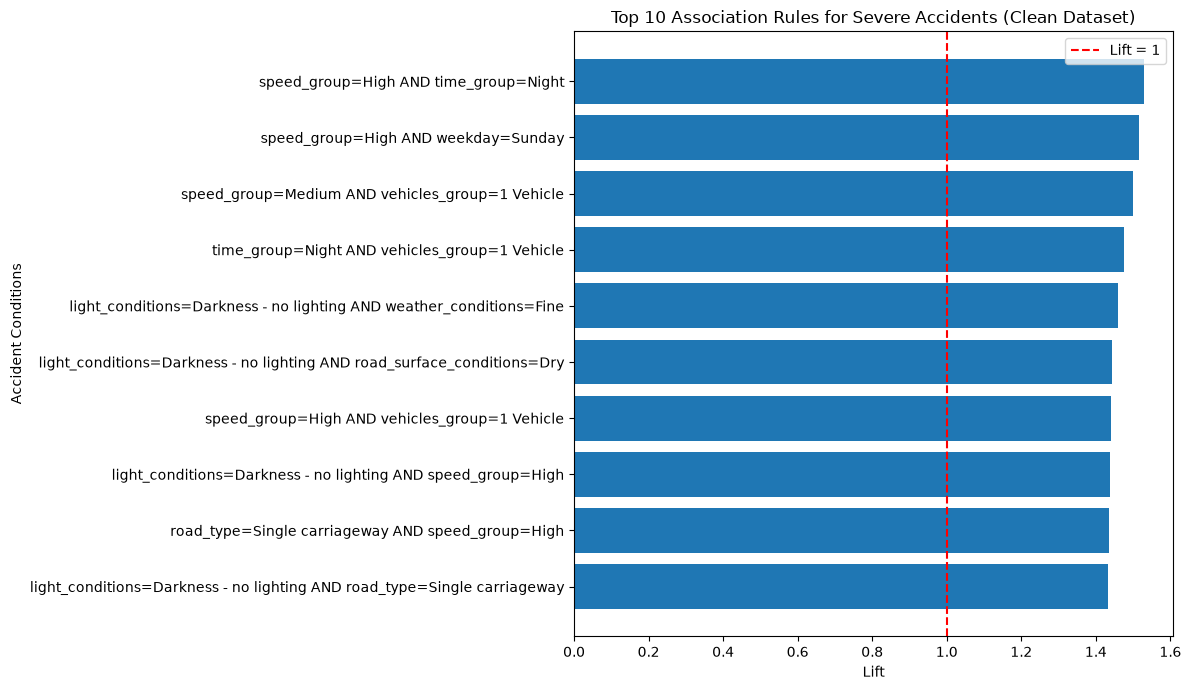

In [8]:

# STEP 29: Visualize Top 10 Severe Rules

import matplotlib.pyplot as plt

# Sort rules for horizontal visualization
plot_data = top_rules_clean.sort_values(
    by="lift",
    ascending=True
)

# Create the chart
plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["Conditions"],
    plot_data["lift"]
)

# Reference line
plt.axvline(
    x=1,
    color="red",
    linestyle="--",
    label="Lift = 1"
)

plt.xlabel("Lift")
plt.ylabel("Accident Conditions")

plt.title(
    "Top 10 Association Rules for Severe Accidents (Clean Dataset)"
)

plt.legend()
plt.tight_layout()
plt.show()


In [9]:

# STEP 30: Final Apriori Evaluation

baseline_clean = (
    clean_apriori_df["severity_group"] == "Severe"
).mean()

print("FINAL APRIORI EVALUATION")
print("========================")

print("Total Accidents:", len(clean_apriori_df))
print(f"Baseline Severe Rate: {baseline_clean:.2%}")

print("Frequent Itemsets:", len(frequent_itemsets_clean))
print("Total Association Rules:", len(rules_clean))
print("Rules Ending in Severe:", len(severe_rules_clean))
print("Positive Severe Rules:", len(positive_severe_rules_clean))

print("\nSTRONGEST RULE")
best_rule = top_rules_clean.iloc[0]

print("Conditions:", best_rule["Conditions"])
print(f"Support: {best_rule['support']:.2%}")
print(f"Confidence: {best_rule['confidence']:.2%}")
print(f"Lift: {best_rule['lift']:.3f}")



FINAL APRIORI EVALUATION
Total Accidents: 101523
Baseline Severe Rate: 26.24%
Frequent Itemsets: 6018
Total Association Rules: 14365
Rules Ending in Severe: 493
Positive Severe Rules: 266

STRONGEST RULE
Conditions: speed_group=High AND time_group=Night
Support: 0.50%
Confidence: 40.16%
Lift: 1.530
